In [ ]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "best.pt" in files:
        print(os.path.join(root, "best.pt"))

/content/drive/MyDrive/best.pt


In [ ]:
import os

files = os.listdir("/content/drive/MyDrive")

for file in files:
    print(file)

Colab Notebooks
Sheet 1.pdf
Sheet 2.pdf
Sheet _3.pdf
Sheet 4.pdf
Google AI Studio
تصميم بطاقة تعريف جامعية.gsheet
ورقة إجابة شبكات الحاسوب جاهزة.gsheet
malake.drawio.pdf
malakelsherbiny.drawio.pdf
ENGmalakelsherbiny.drawio.pdf
malakELsherbiny.drawio.pdf
malake-Page-2.drawio.png
malake-Page-1.drawio.png
malake-Page-3.drawio.png
malake.drawio
Classroom
Assignment 2 (28 Jul 2026 at 22:40)(2).jpg
Assignment 2 (28 Jul 2026 at 22:40)(3).jpg
IMG_1259 (1).jpeg
IMG_1259.jpeg
IMG_1262.jpeg
IMG_1276.jpeg
Faculty of Artificial Intelligence - Training Form.gdoc
Training Details Form - Faculty of Artificial Intelligence.gdoc
Training Details Form V2 - Faculty of Artificial Intelligence.gdoc
Faculty_Logo.jpeg
Malak_Yasser_CV.docx.gdoc
Malak_Yasser_CV_OnePage.docx.gdoc
Malak_Yasser_CV_Pro.docx.gdoc
Malak_Yasser_CV_Classic_OnePage.docx.gdoc
data.yaml
Fire-Smoke-Detection-Yolov11.v1-smoke-fire-detection.yolov8
Copy of Fire-Smoke-Detection-Yolov11.v1-smoke-fire-detection.yolov8
Fire-Smoke-Detection-Yolo

In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/Fire-Smoke-Dataset-Reduced.zip"
extract_path = "/content/fire_smoke_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
import os

dataset_path = "/content/fire_smoke_dataset"

for item in os.listdir(dataset_path):
    print(item)

Fire-Smoke-Dataset-Reduced


In [ ]:
dataset_path = "/content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced"

import os

for item in os.listdir(dataset_path):
    print(item)

data.yaml
test
labels_backup_before_conversion
train
valid


In [ ]:
yaml_path = "/content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/data.yaml"

with open(yaml_path, "r") as f:
    print(f.read())

train: train/images
val: valid/images
test: test/images

nc: 2
names: ['Fire', 'Smoke']


In [ ]:
import os

dataset_path = "/content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced"

for folder in ["train", "valid", "test"]:
    images_path = os.path.join(dataset_path, folder, "images")
    labels_path = os.path.join(dataset_path, folder, "labels")

    print(f"\n{folder.upper()}")
    print("Images:", len(os.listdir(images_path)))
    print("Labels:", len(os.listdir(labels_path)))


TRAIN
Images: 5000
Labels: 5000

VALID
Images: 871
Labels: 871

TEST
Images: 434
Labels: 434


In [ ]:
!pip install ultralytics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 11.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

print("YOLO is ready!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO is ready!


In [ ]:
model = YOLO("yolov8n.pt")

In [ ]:
results = model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    device=0
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None,

In [ ]:
best_model = YOLO("/content/runs/detect/train/weights/best.pt")

metrics = best_model.val(
    data=yaml_path,
    split="val",
    imgsz=640,
    device=0
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1544.8±569.1 MB/s, size: 55.5 KB)
val: Scanning /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/valid/labels.cache... 871 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 871/871 281.0Mit/s 0.0s
val: /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/valid/images/0111_jpg.rf.df9ecd8f7faed94e97c5a56527701e05.jpg: 1 duplicate labels removed
val: /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/valid/images/52_jpg.rf.f27ed8ca965c7261933cc61528cd6a0a.jpg: 1 duplicate labels removed
val: /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/valid/images/Img_1060_jpg.rf.d53273be278b74366e9ae2bfca25f709.jpg: 1 duplicate labels removed
val: /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/valid/images/Img_1169_jpg.rf.ad38a3b517eeced6a0412e60069c01dc.jpg: 2 

In [ ]:
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Precision: 0.7693999800938047
Recall: 0.6870466458340102
mAP50: 0.7378039548706028
mAP50-95: 0.4448848090939159


In [ ]:
test_metrics = best_model.val(
    data=yaml_path,
    split="test",
    imgsz=640,
    device=0,
    plots=True
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1194.7±412.9 MB/s, size: 45.1 KB)
val: Scanning /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/test/labels... 434 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 434/434 1.7Kit/s 0.3s
val: /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/test/images/Img_1039_jpg.rf.6c174491ecb5b2ab7c968c49ed4918ea.jpg: 1 duplicate labels removed
val: /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/test/images/Img_1166_jpg.rf.d71ad2b922967dbb6ee59be88f618980.jpg: 4 duplicate labels removed
val: /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/test/images/Img_1196_jpg.rf.4c8c7963afdb2c3759b4ae188042cc54.jpg: 1 duplicate labels removed
val: /content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/test/images/Img_423_jpg.rf.949f27f164200f50a2abf8a51f72487c.jpg: 2 dupl

In [ ]:
import os

print(os.listdir("/content/runs/detect/val-2"))

['BoxPR_curve.png', 'BoxF1_curve.png', 'val_batch2_labels.jpg', 'val_batch1_pred.jpg', 'BoxP_curve.png', 'val_batch2_pred.jpg', 'confusion_matrix_normalized.png', 'val_batch0_pred.jpg', 'val_batch0_labels.jpg', 'confusion_matrix.png', 'BoxR_curve.png', 'val_batch1_labels.jpg']


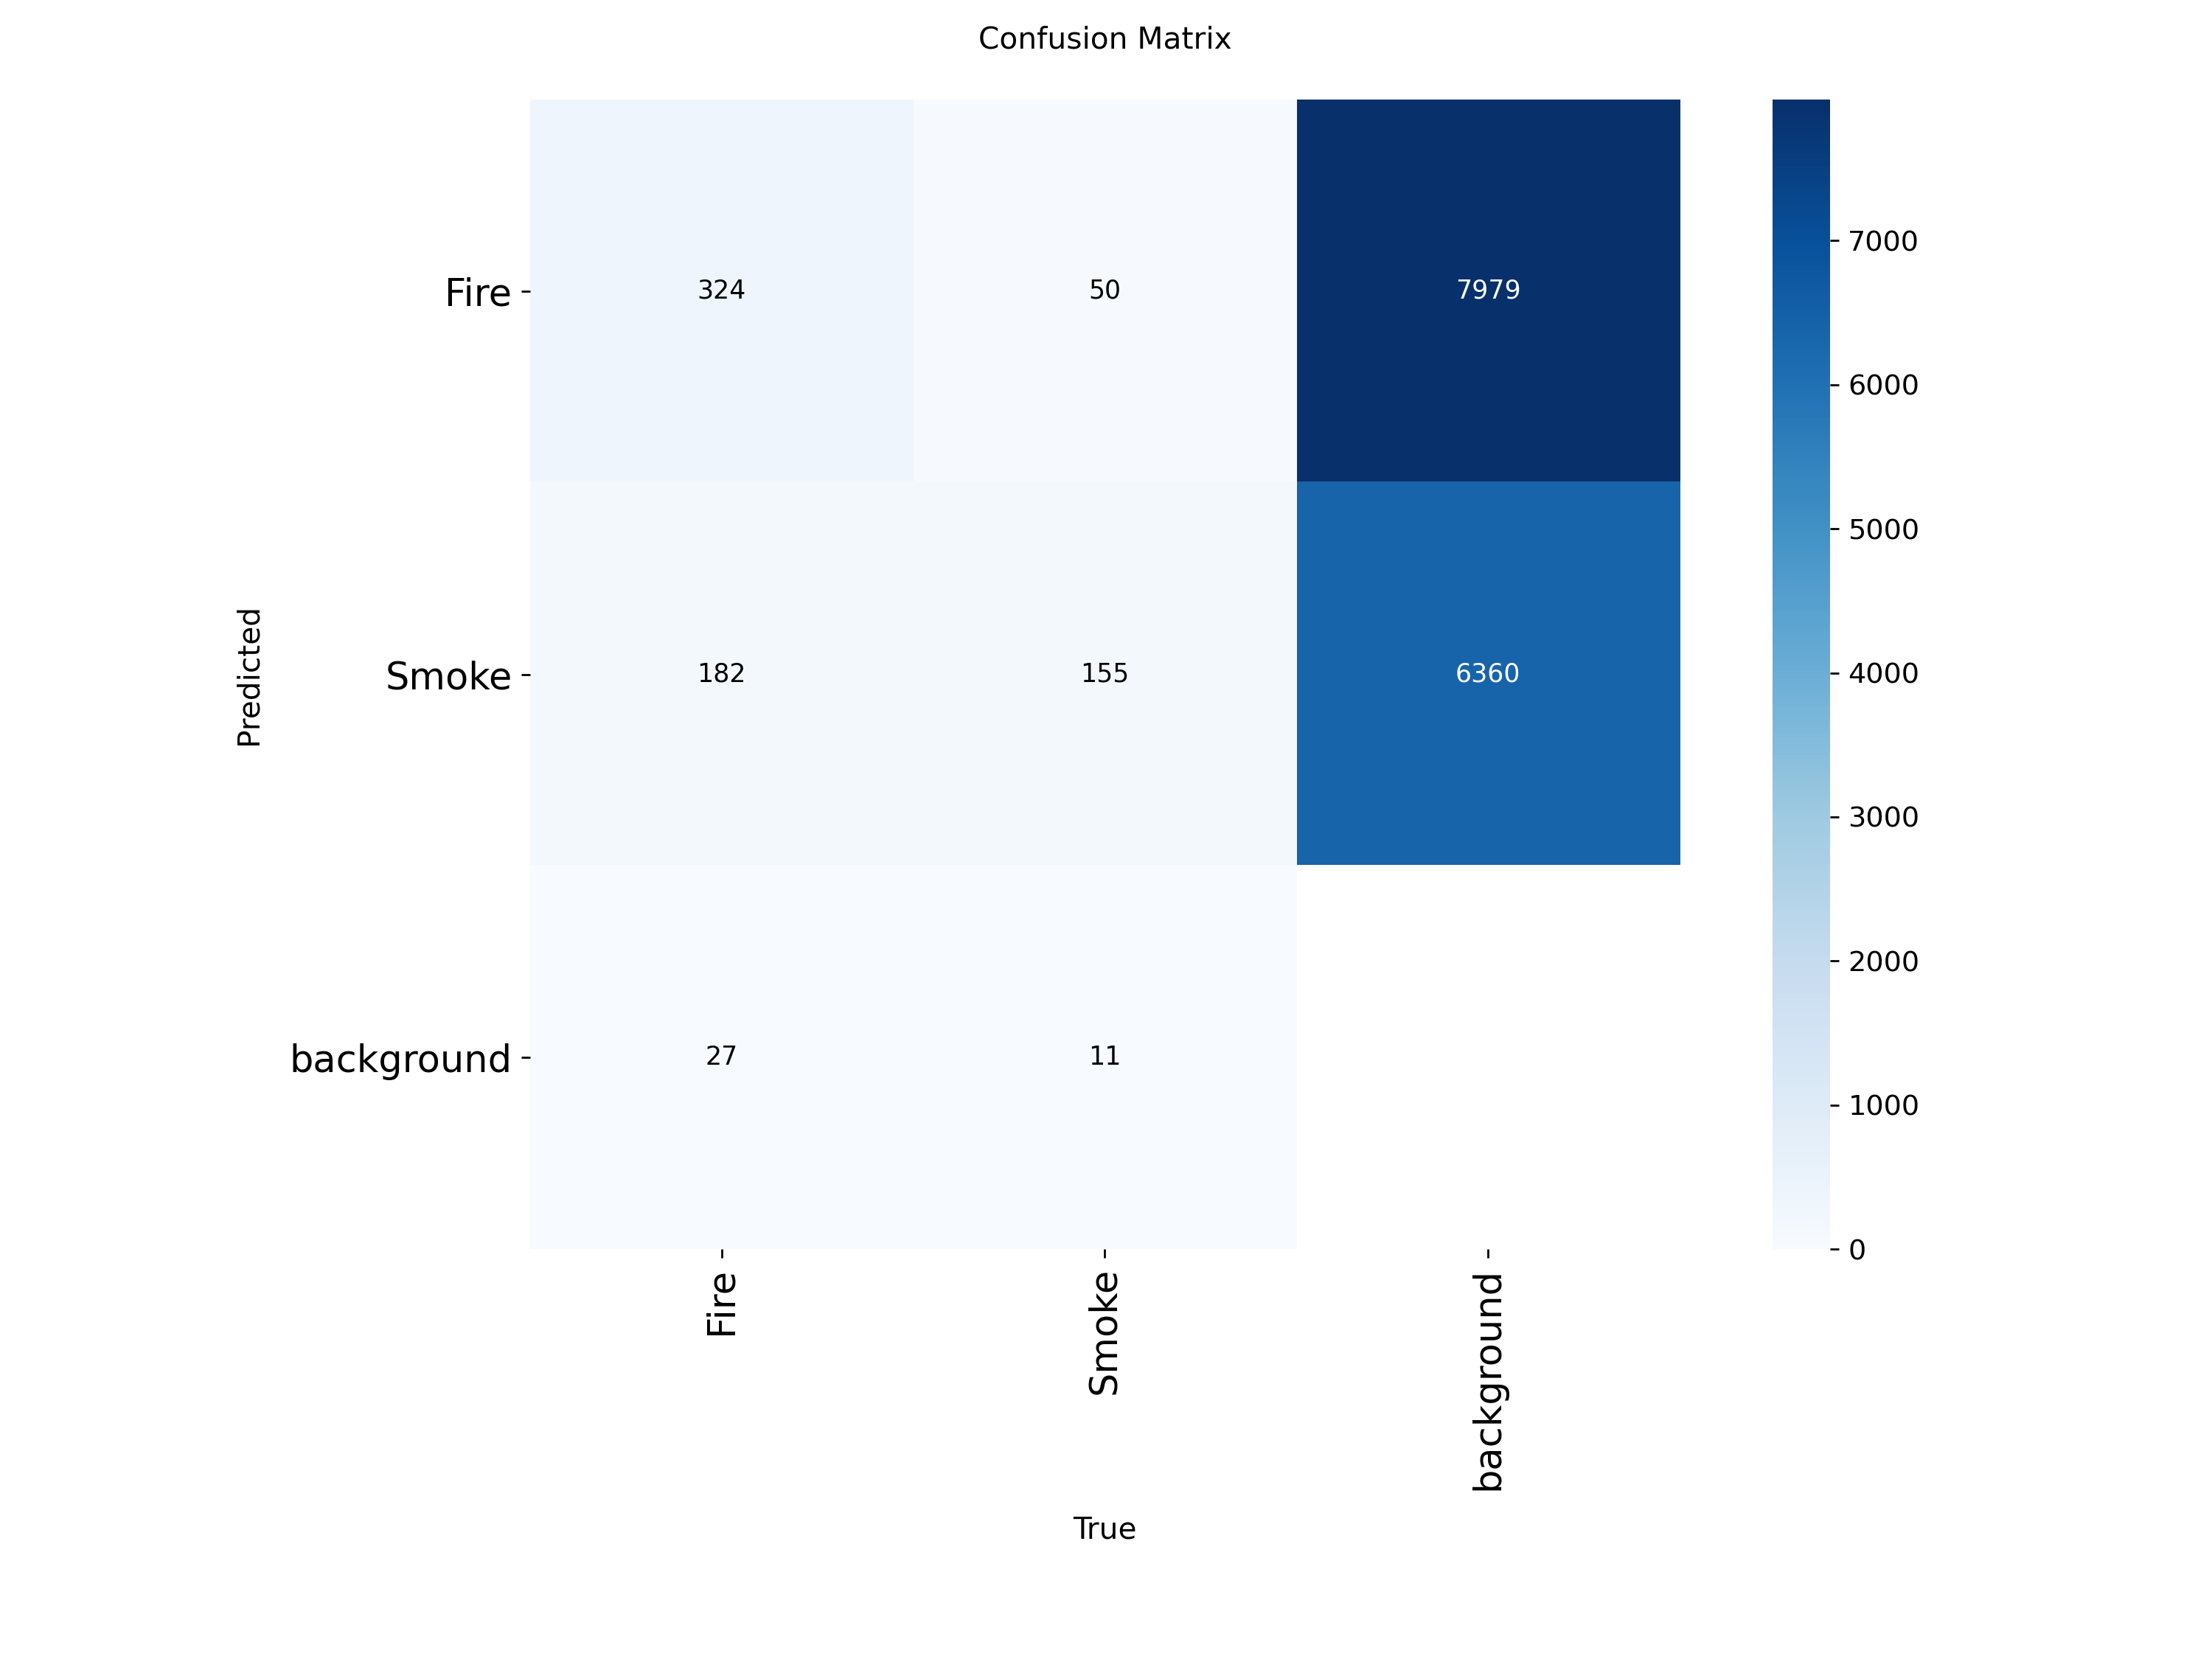

In [ ]:
from IPython.display import Image, display

display(Image("/content/runs/detect/val-2/confusion_matrix.png"))

In [ ]:
from ultralytics import YOLO

best_model = YOLO("/content/runs/detect/train/weights/best.pt")

print("Model loaded successfully ✅")

Model loaded successfully ✅


In [ ]:
import numpy as np

test_results = best_model.predict(
    source="/content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/test/images",
    imgsz=640,
    conf=0.25,
    device=0,
    save=False,
    verbose=False
)

print("Predictions completed ✅")

Predictions completed ✅


In [ ]:
import os
import numpy as np

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


test_images = "/content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/test/images"
test_labels = "/content/fire_smoke_dataset/Fire-Smoke-Dataset-Reduced/test/labels"

ious = []

for result in test_results:
    image_path = result.path
    image_name = os.path.splitext(os.path.basename(image_path))[0]
    label_path = os.path.join(test_labels, image_name + ".txt")

    if not os.path.exists(label_path):
        continue

    img_h, img_w = result.orig_shape

    ground_truth = []

    with open(label_path, "r") as f:
        for line in f:
            values = line.strip().split()
            if len(values) != 5:
                continue

            cls, xc, yc, w, h = map(float, values)

            x1 = (xc - w / 2) * img_w
            y1 = (yc - h / 2) * img_h
            x2 = (xc + w / 2) * img_w
            y2 = (yc + h / 2) * img_h

            ground_truth.append((int(cls), [x1, y1, x2, y2]))

    predictions = []

    for box, cls in zip(result.boxes.xyxy.cpu().numpy(),
                         result.boxes.cls.cpu().numpy()):
        predictions.append((int(cls), box))

    matched = set()

    for gt_cls, gt_box in ground_truth:
        best_iou = 0
        best_idx = -1

        for i, (pred_cls, pred_box) in enumerate(predictions):
            if i in matched or pred_cls != gt_cls:
                continue

            iou = calculate_iou(gt_box, pred_box)

            if iou > best_iou:
                best_iou = iou
                best_idx = i

        if best_idx != -1:
            matched.add(best_idx)
            ious.append(best_iou)

if ious:
    mean_iou = np.mean(ious)
    print(f"Mean IoU: {mean_iou:.4f}")
    print(f"Mean IoU (%): {mean_iou * 100:.2f}%")
else:
    print("No matched boxes found.")

Mean IoU: 0.7371
Mean IoU (%): 73.71%


In [ ]:
import os
import shutil

drive_folder = "/content/drive/MyDrive/Fire-Smoke-Project"

os.makedirs(drive_folder, exist_ok=True)

files_to_save = [
    "/content/runs/detect/train/weights/best.pt",
    "/content/runs/detect/train/results.csv",
    "/content/runs/detect/train/results.png",
    "/content/runs/detect/val-2/confusion_matrix.png",
    "/content/runs/detect/val-2/confusion_matrix_normalized.png",
    "/content/runs/detect/val-2/BoxP_curve.png",
    "/content/runs/detect/val-2/BoxR_curve.png",
    "/content/runs/detect/val-2/BoxF1_curve.png",
    "/content/runs/detect/val-2/BoxPR_curve.png"
]

for file_path in files_to_save:
    if os.path.exists(file_path):
        shutil.copy2(file_path, drive_folder)

print("All important project files saved to Google Drive ✅")
print(drive_folder)

All important project files saved to Google Drive ✅
/content/drive/MyDrive/Fire-Smoke-Project


In [ ]:
import os

folder = "/content/drive/MyDrive/Fire-Smoke-Project"
print(os.listdir(folder))

['best.pt', 'results.csv', 'results.png', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'BoxP_curve.png', 'BoxR_curve.png', 'BoxF1_curve.png', 'BoxPR_curve.png']


In [ ]:
from ultralytics import YOLO

best_model = YOLO("/content/drive/MyDrive/best.pt")

print("Model loaded successfully ✅")

Model loaded successfully ✅


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "data.yaml" in files:
        print(os.path.join(root, "data.yaml"))

/content/drive/MyDrive/data.yaml


In [ ]:
import os

print(os.listdir("/content/drive/MyDrive"))

['Classroom', 'Colab Notebooks', 'Assignment 2.gdoc', 'Screenshot_20260815_163436_com_android_chrome_ChromeTabbedActivity_edit_369063108334003 (1).jpg', 'Screenshot_20260815_163436_com_android_chrome_ChromeTabbedActivity_edit_369063108334003.jpg', 'Screenshot_20260815_163431_com_android_chrome_ChromeTabbedActivity_edit_369033393815785.jpg', 'Screenshot_20260818_021634.jpg', 'AI_Engineering_Day01_Solution-1.pdf', 'Day01.pdf', 'Screenshot_20260907_015649_com_microsoft_office_word_WordActivity_edit_144672922747153.jpg', 'IMG-20260908-WA0004.jpg', 'day4.docx', 'IMG-20260909-WA0020.jpg', 'pizza_game.py', 'day7 (1).pdf', 'day7.pdf', 'best.pt', 'Fire-Smoke-Project', 'data.yaml', 'valid', 'train', 'test', 'labels_backup_before_conversion']


In [ ]:
from ultralytics import YOLO

best_model = YOLO("/content/drive/MyDrive/best.pt")

metrics = best_model.val(
    data="/content/drive/MyDrive/data.yaml",
    split="test",
    imgsz=640,
    device=0,
    plots=True
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.8±0.3 ms, read: 0.1±0.0 MB/s, size: 49.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/.shortcut-targets-by-id/1Dkzdrum7yr3Js7uYRB0F5gii2WNFOQTC/test/labels... 434 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 434/434 2.0it/s 3:39
val: /content/drive/.shortcut-targets-by-id/1Dkzdrum7yr3Js7uYRB0F5gii2WNFOQTC/test/images/Img_1039_jpg.rf.6c174491ecb5b2ab7c968c49ed4918ea.jpg: 1 duplicate labels removed
val: /content/drive/.shortcut-targets-by-id/1Dkzdrum7yr3Js7uYRB0F5gii2WNFOQTC/test/images/Img_1166_jpg.rf.d71ad2b922967dbb6ee59be88f618980.jpg: 4 duplicate labels removed
val: /content/drive/.shortcut-targets-by-id/1Dkzdrum7yr3Js7uYRB0F5gii2WNFOQTC/tes

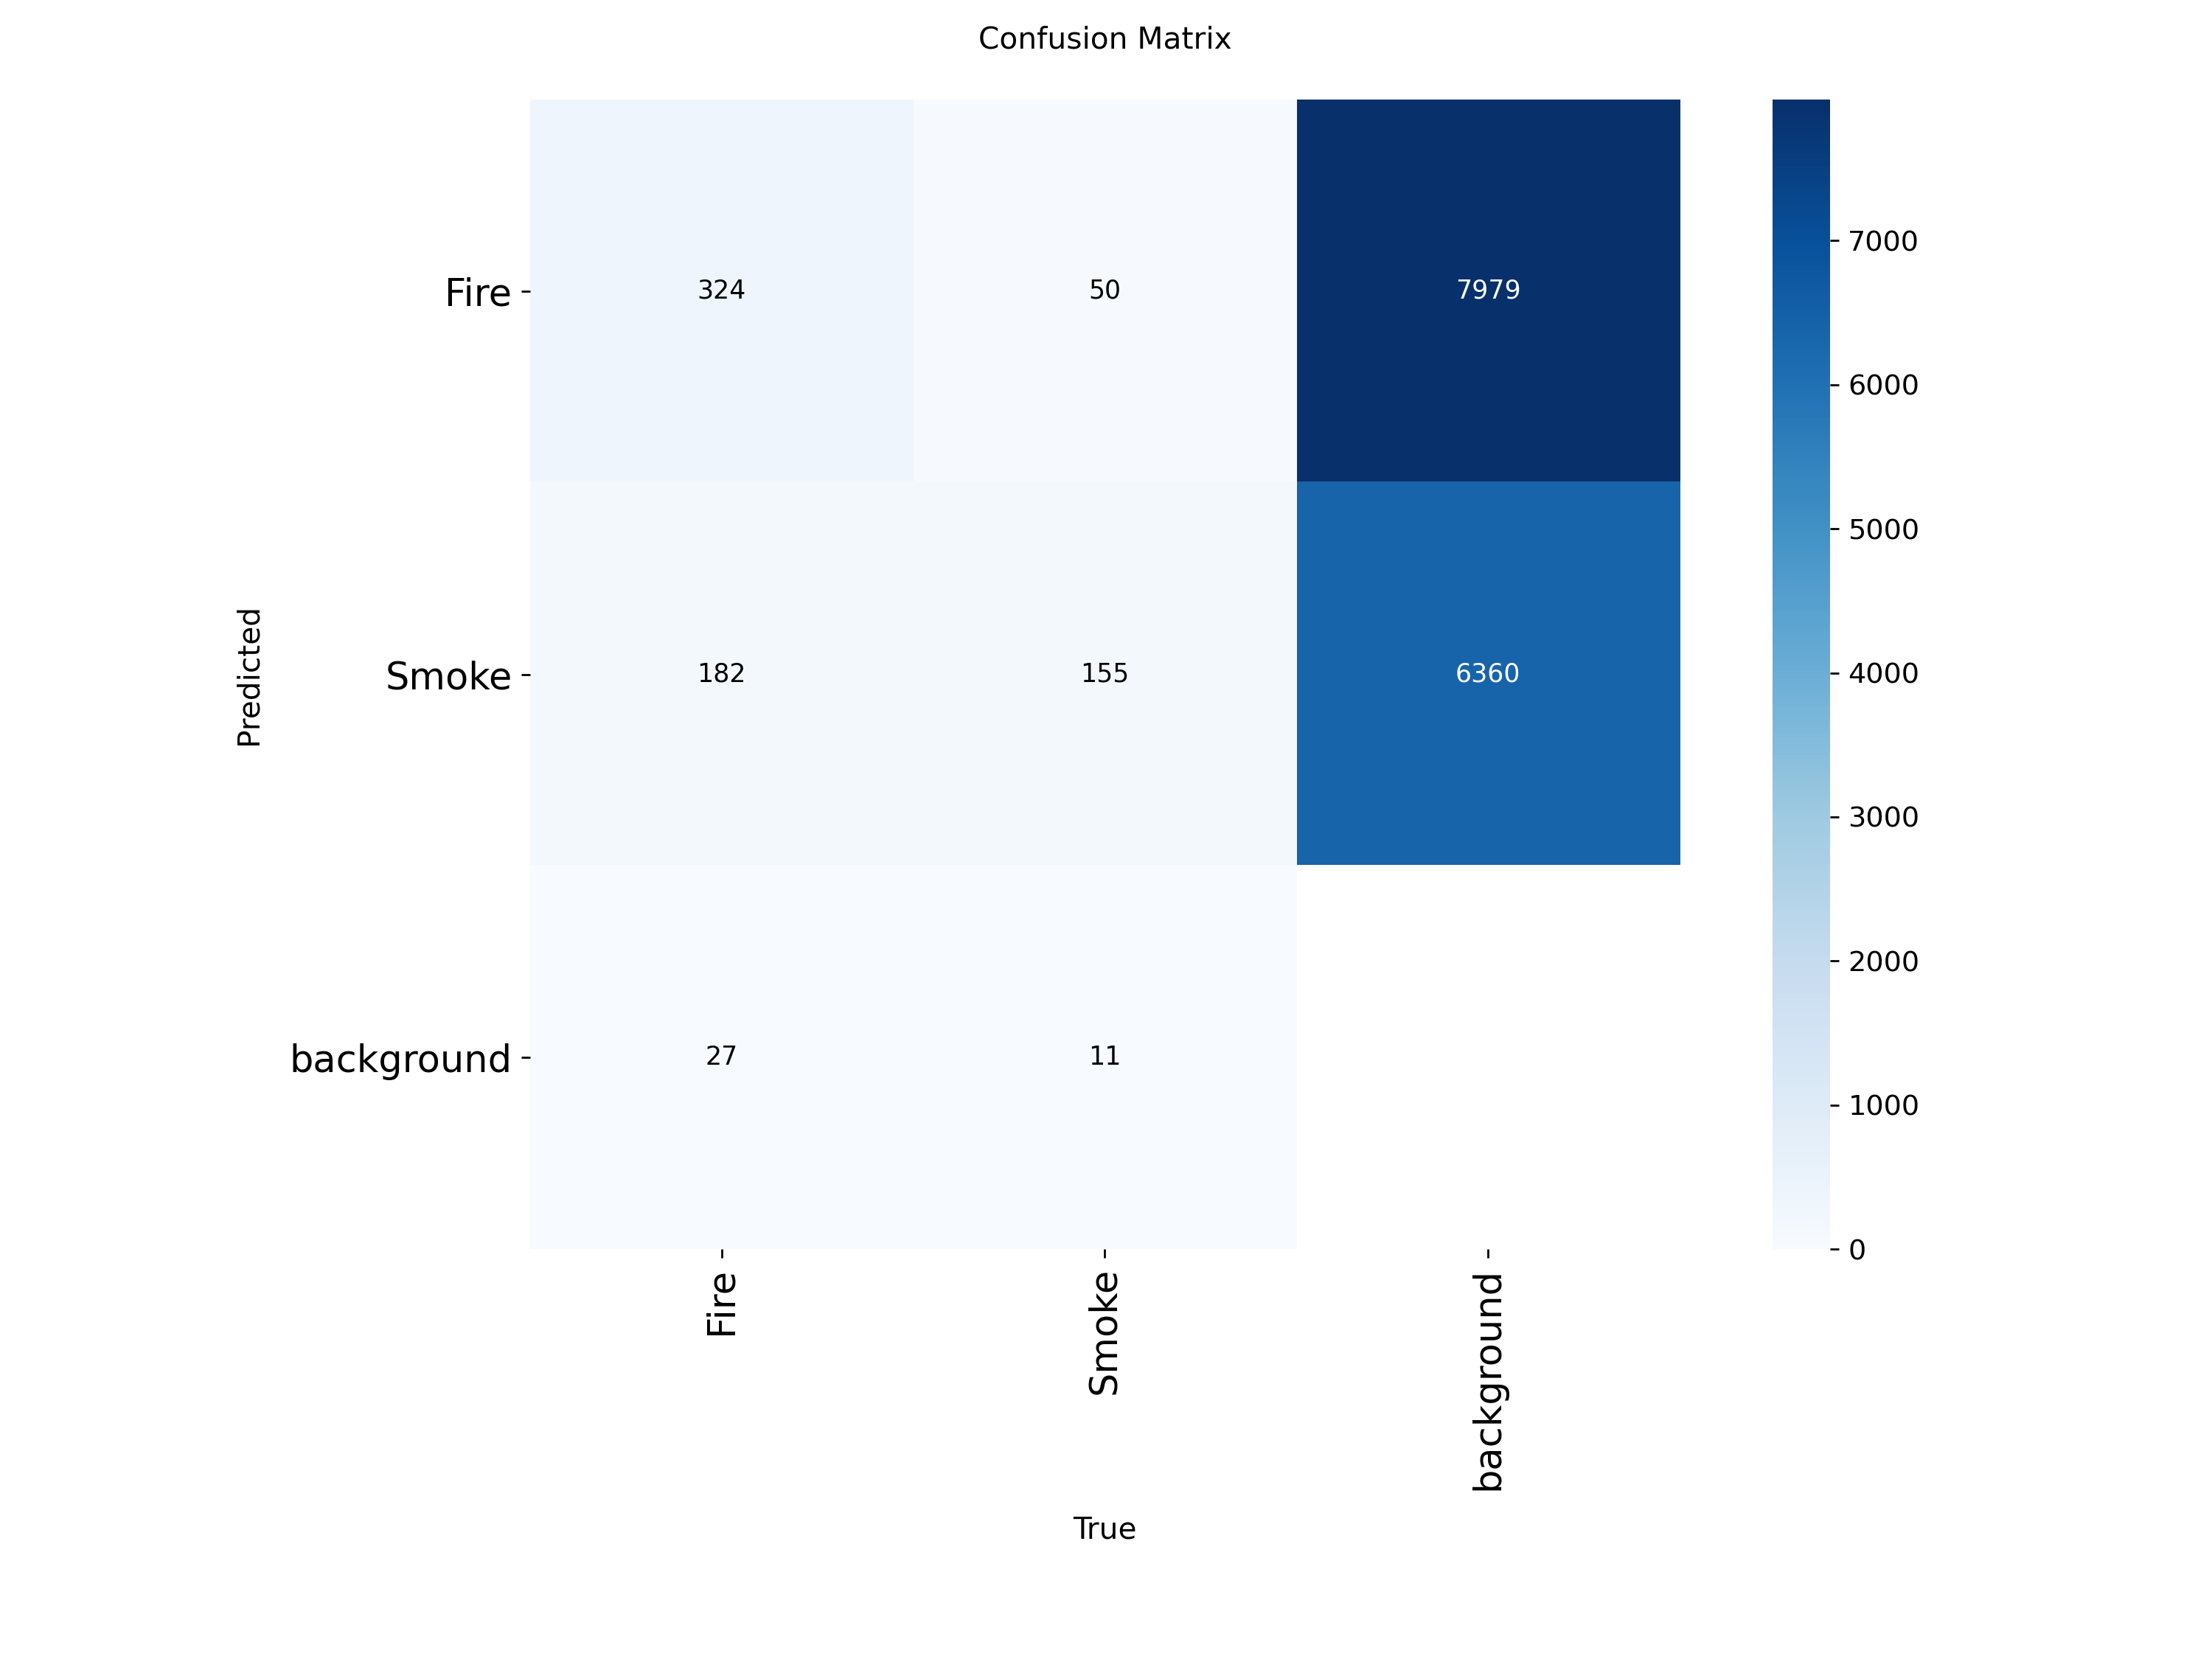

In [ ]:
from IPython.display import Image, display

display(Image("/content/runs/detect/val-2/confusion_matrix.png"))

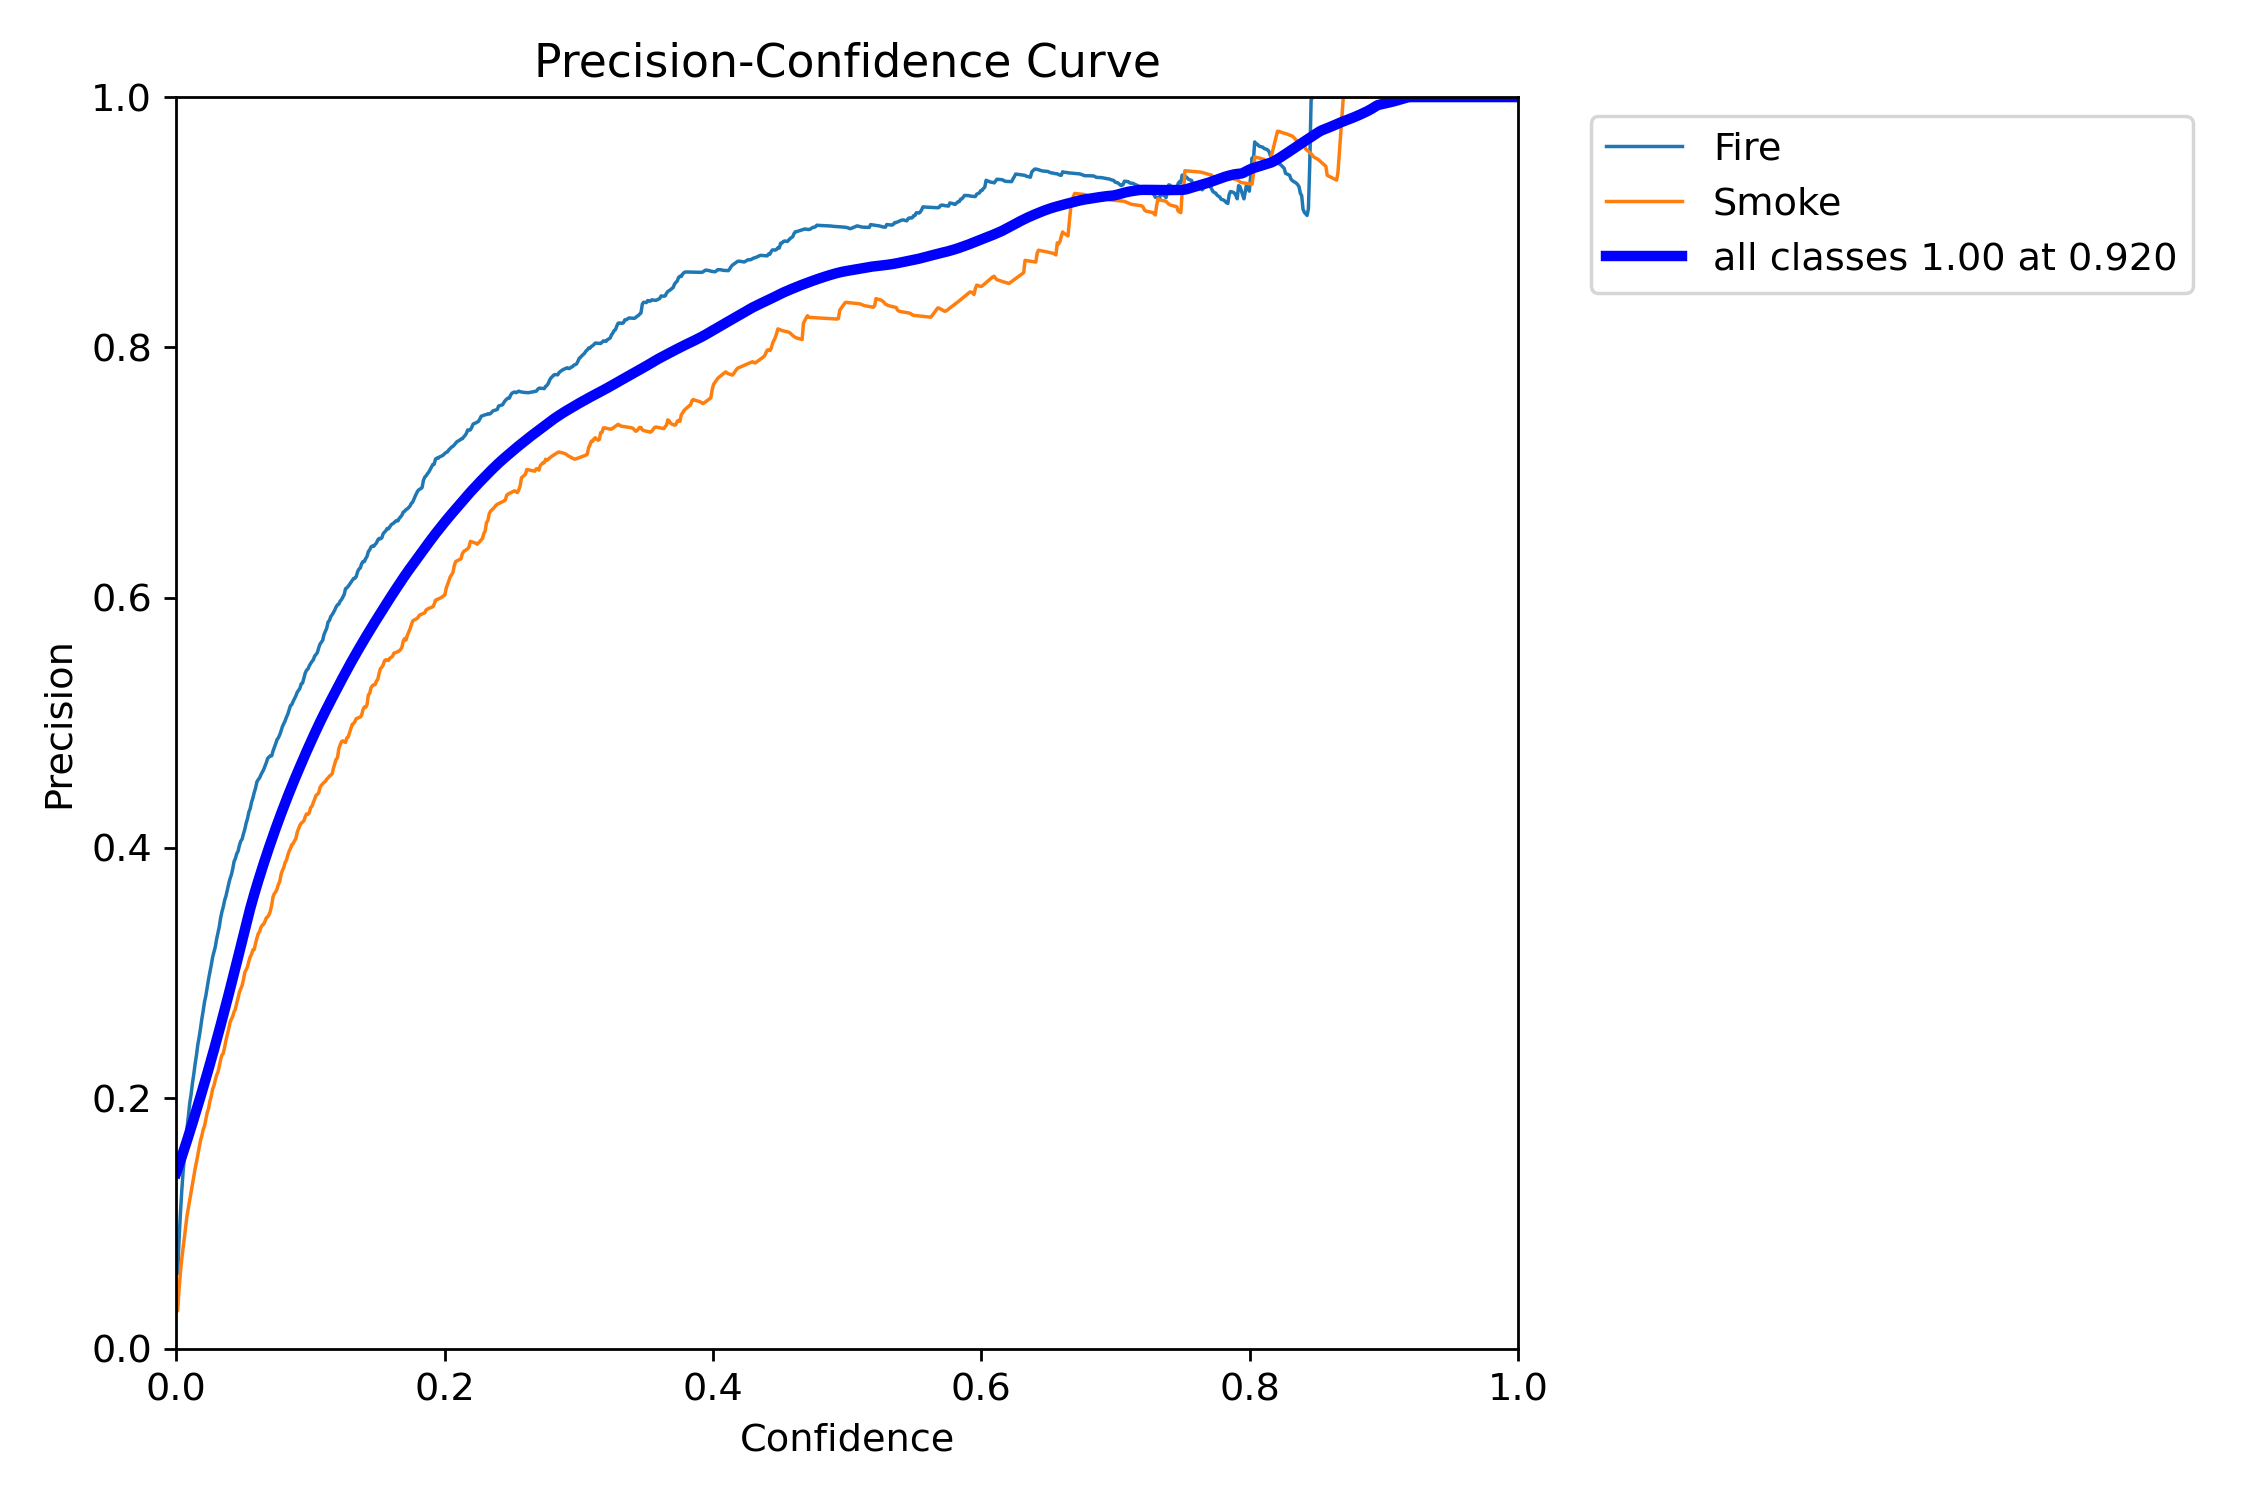

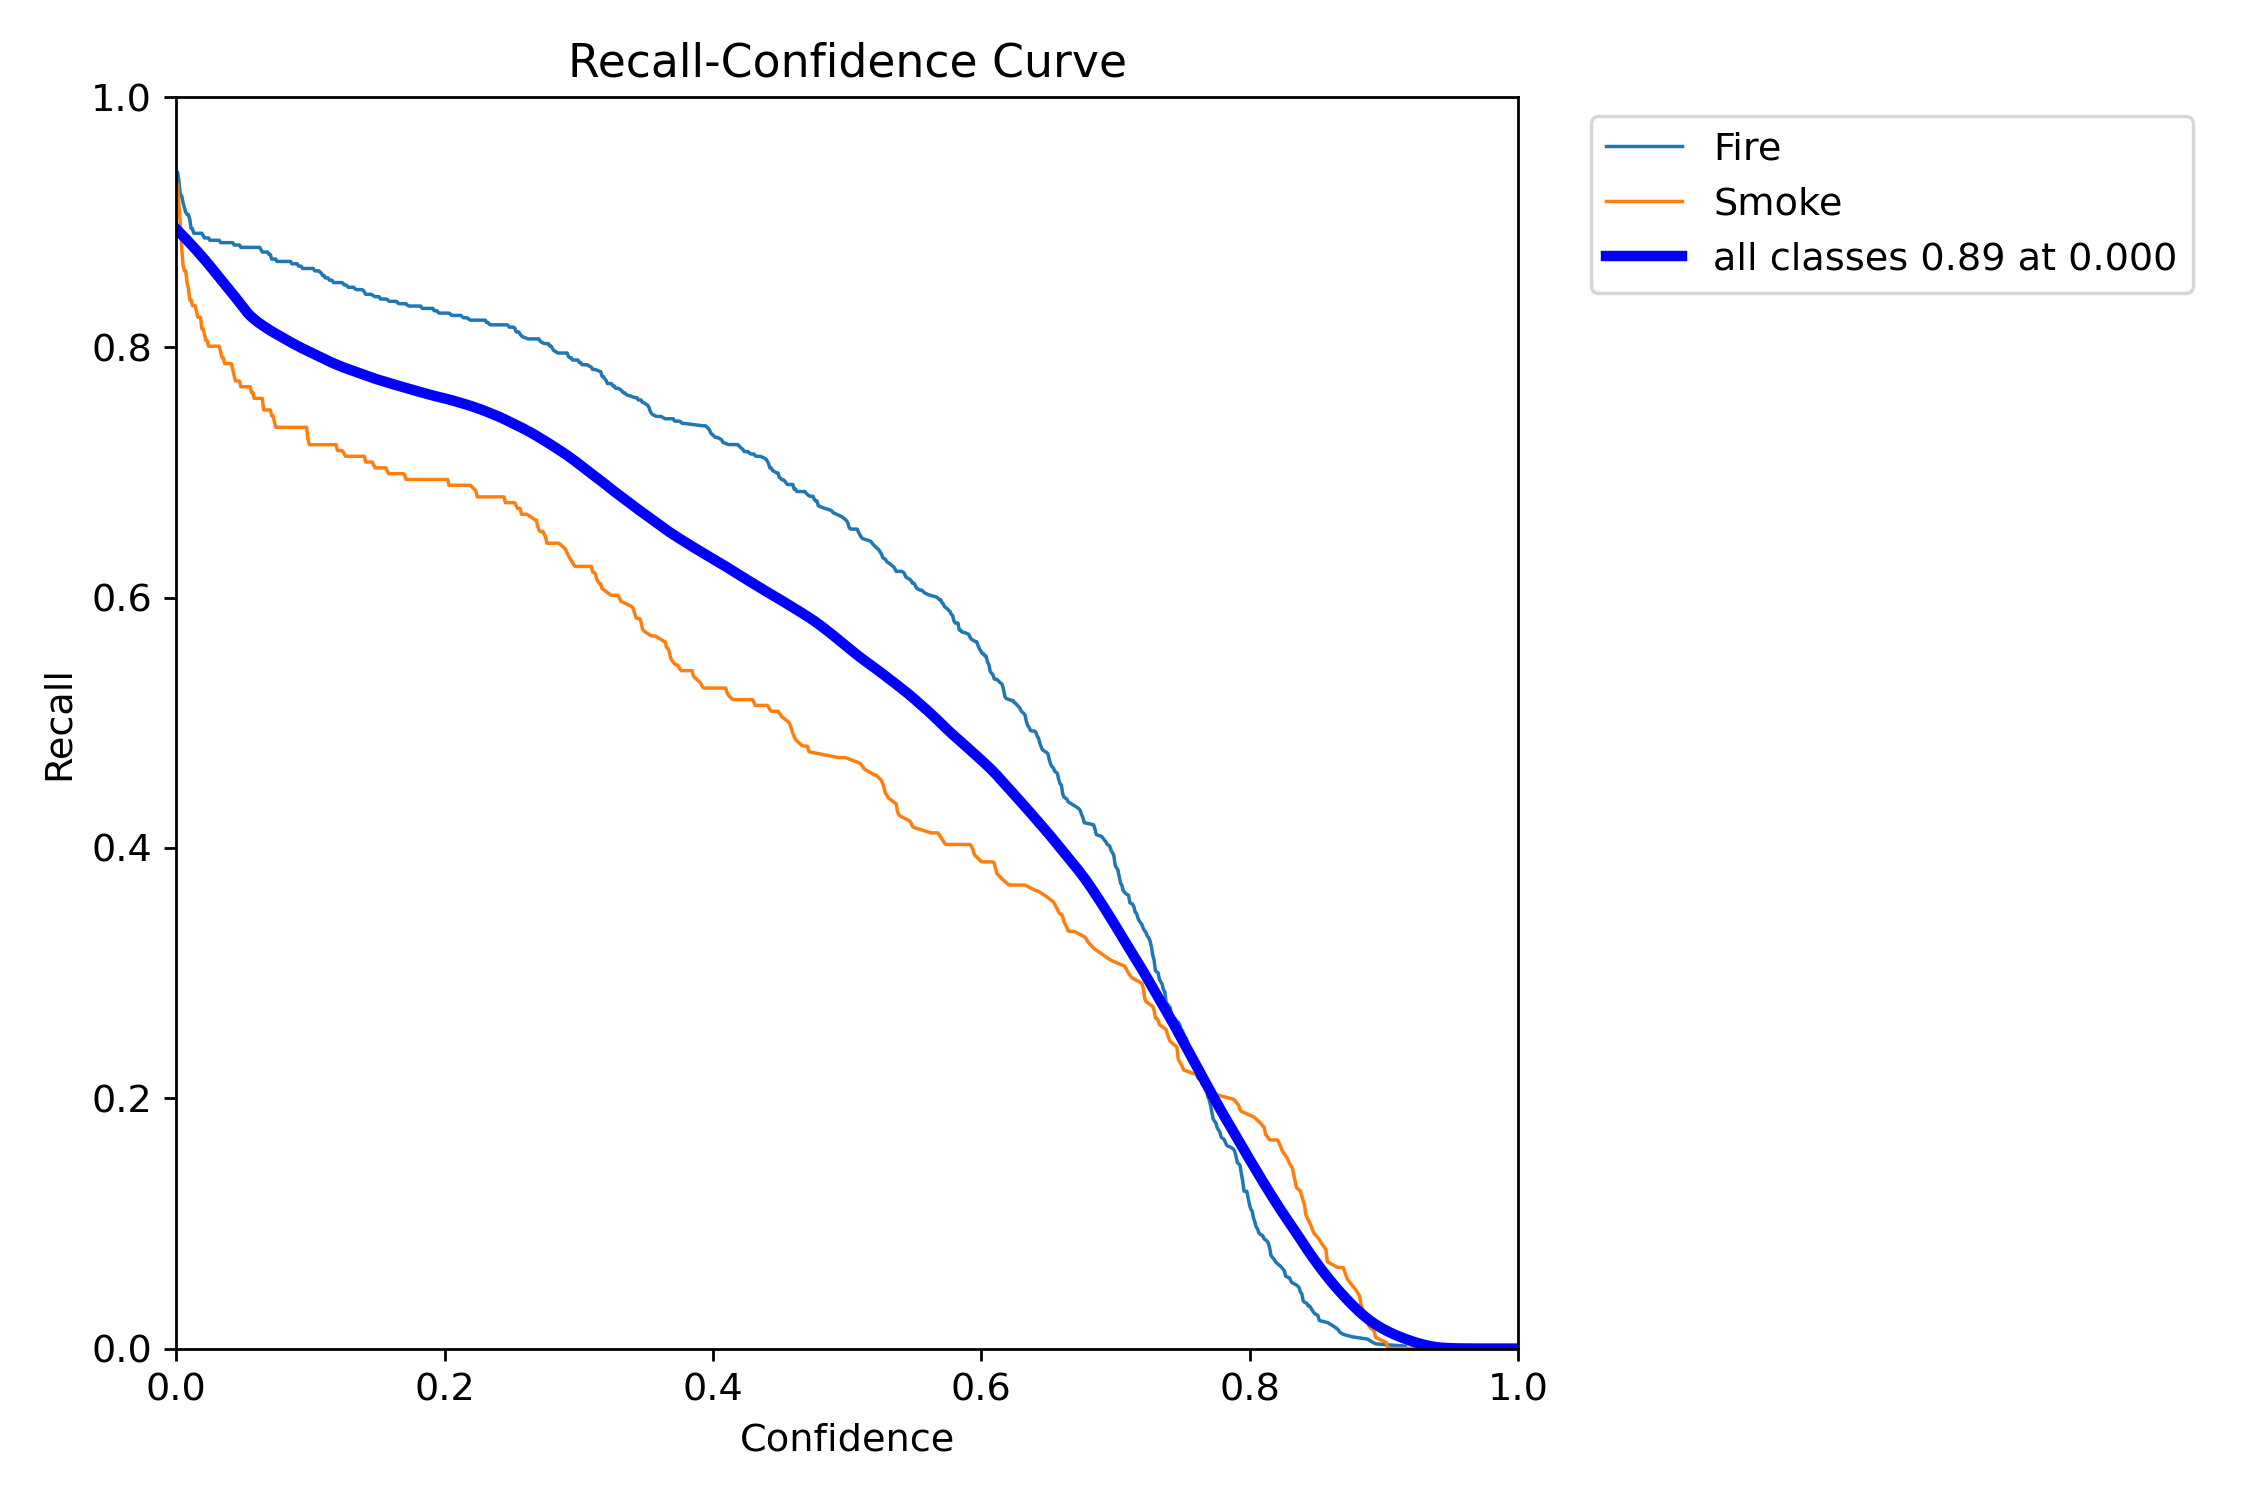

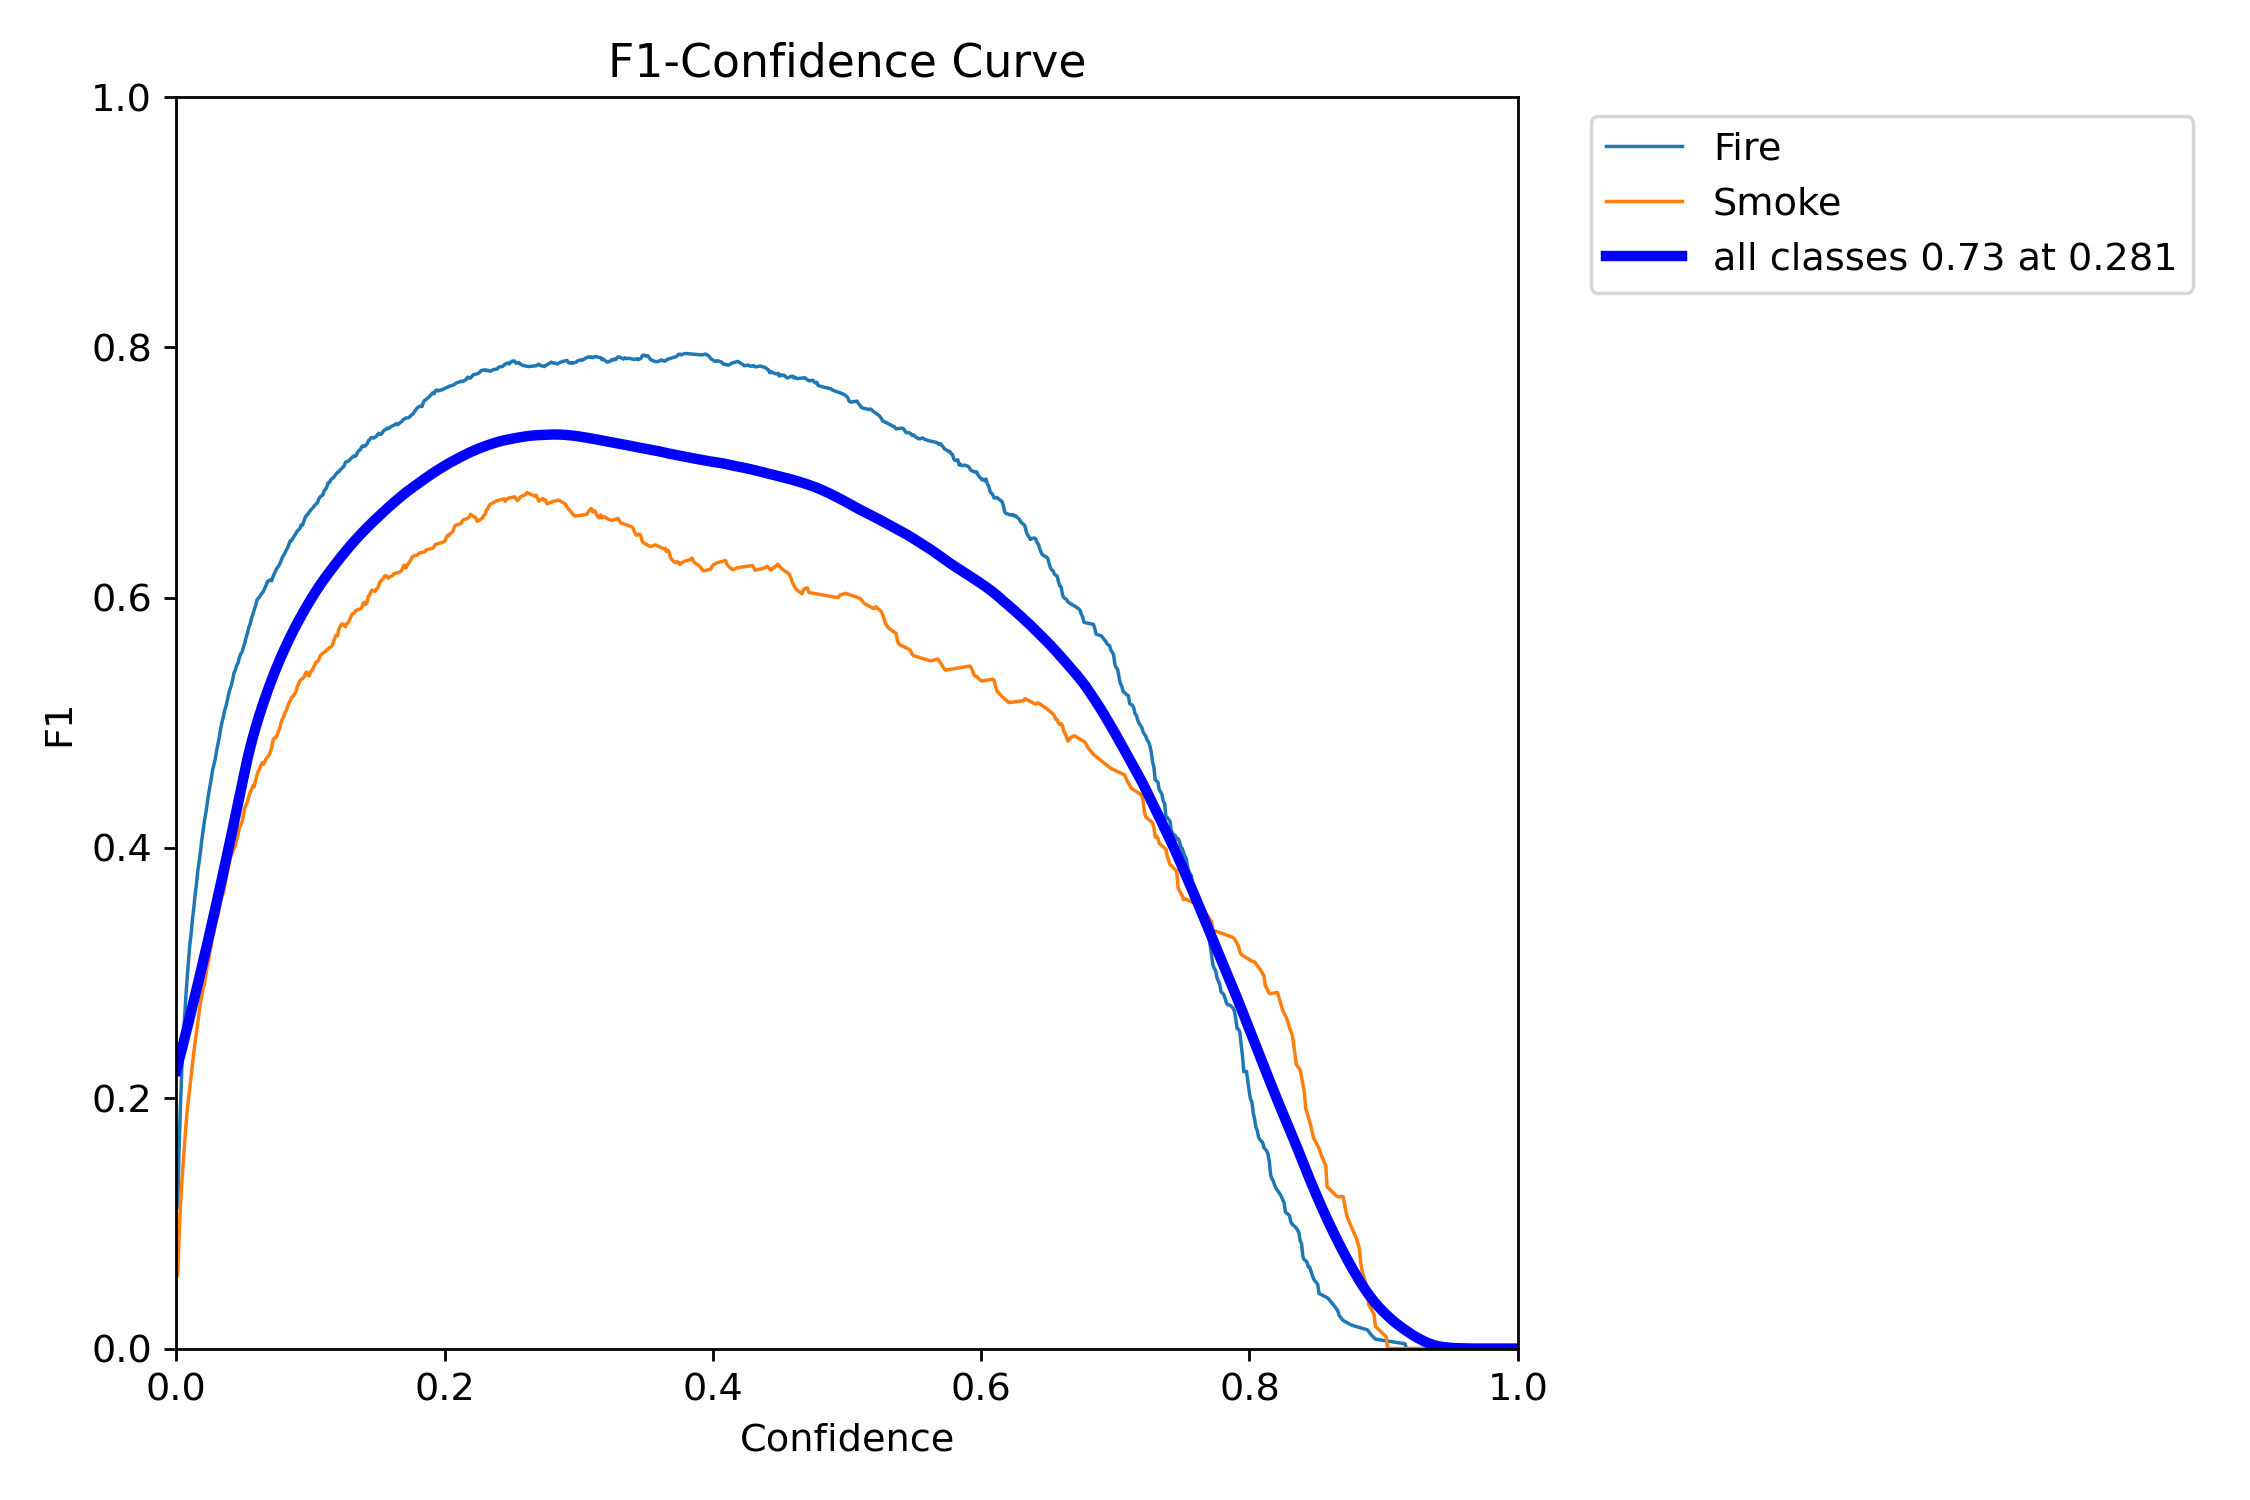

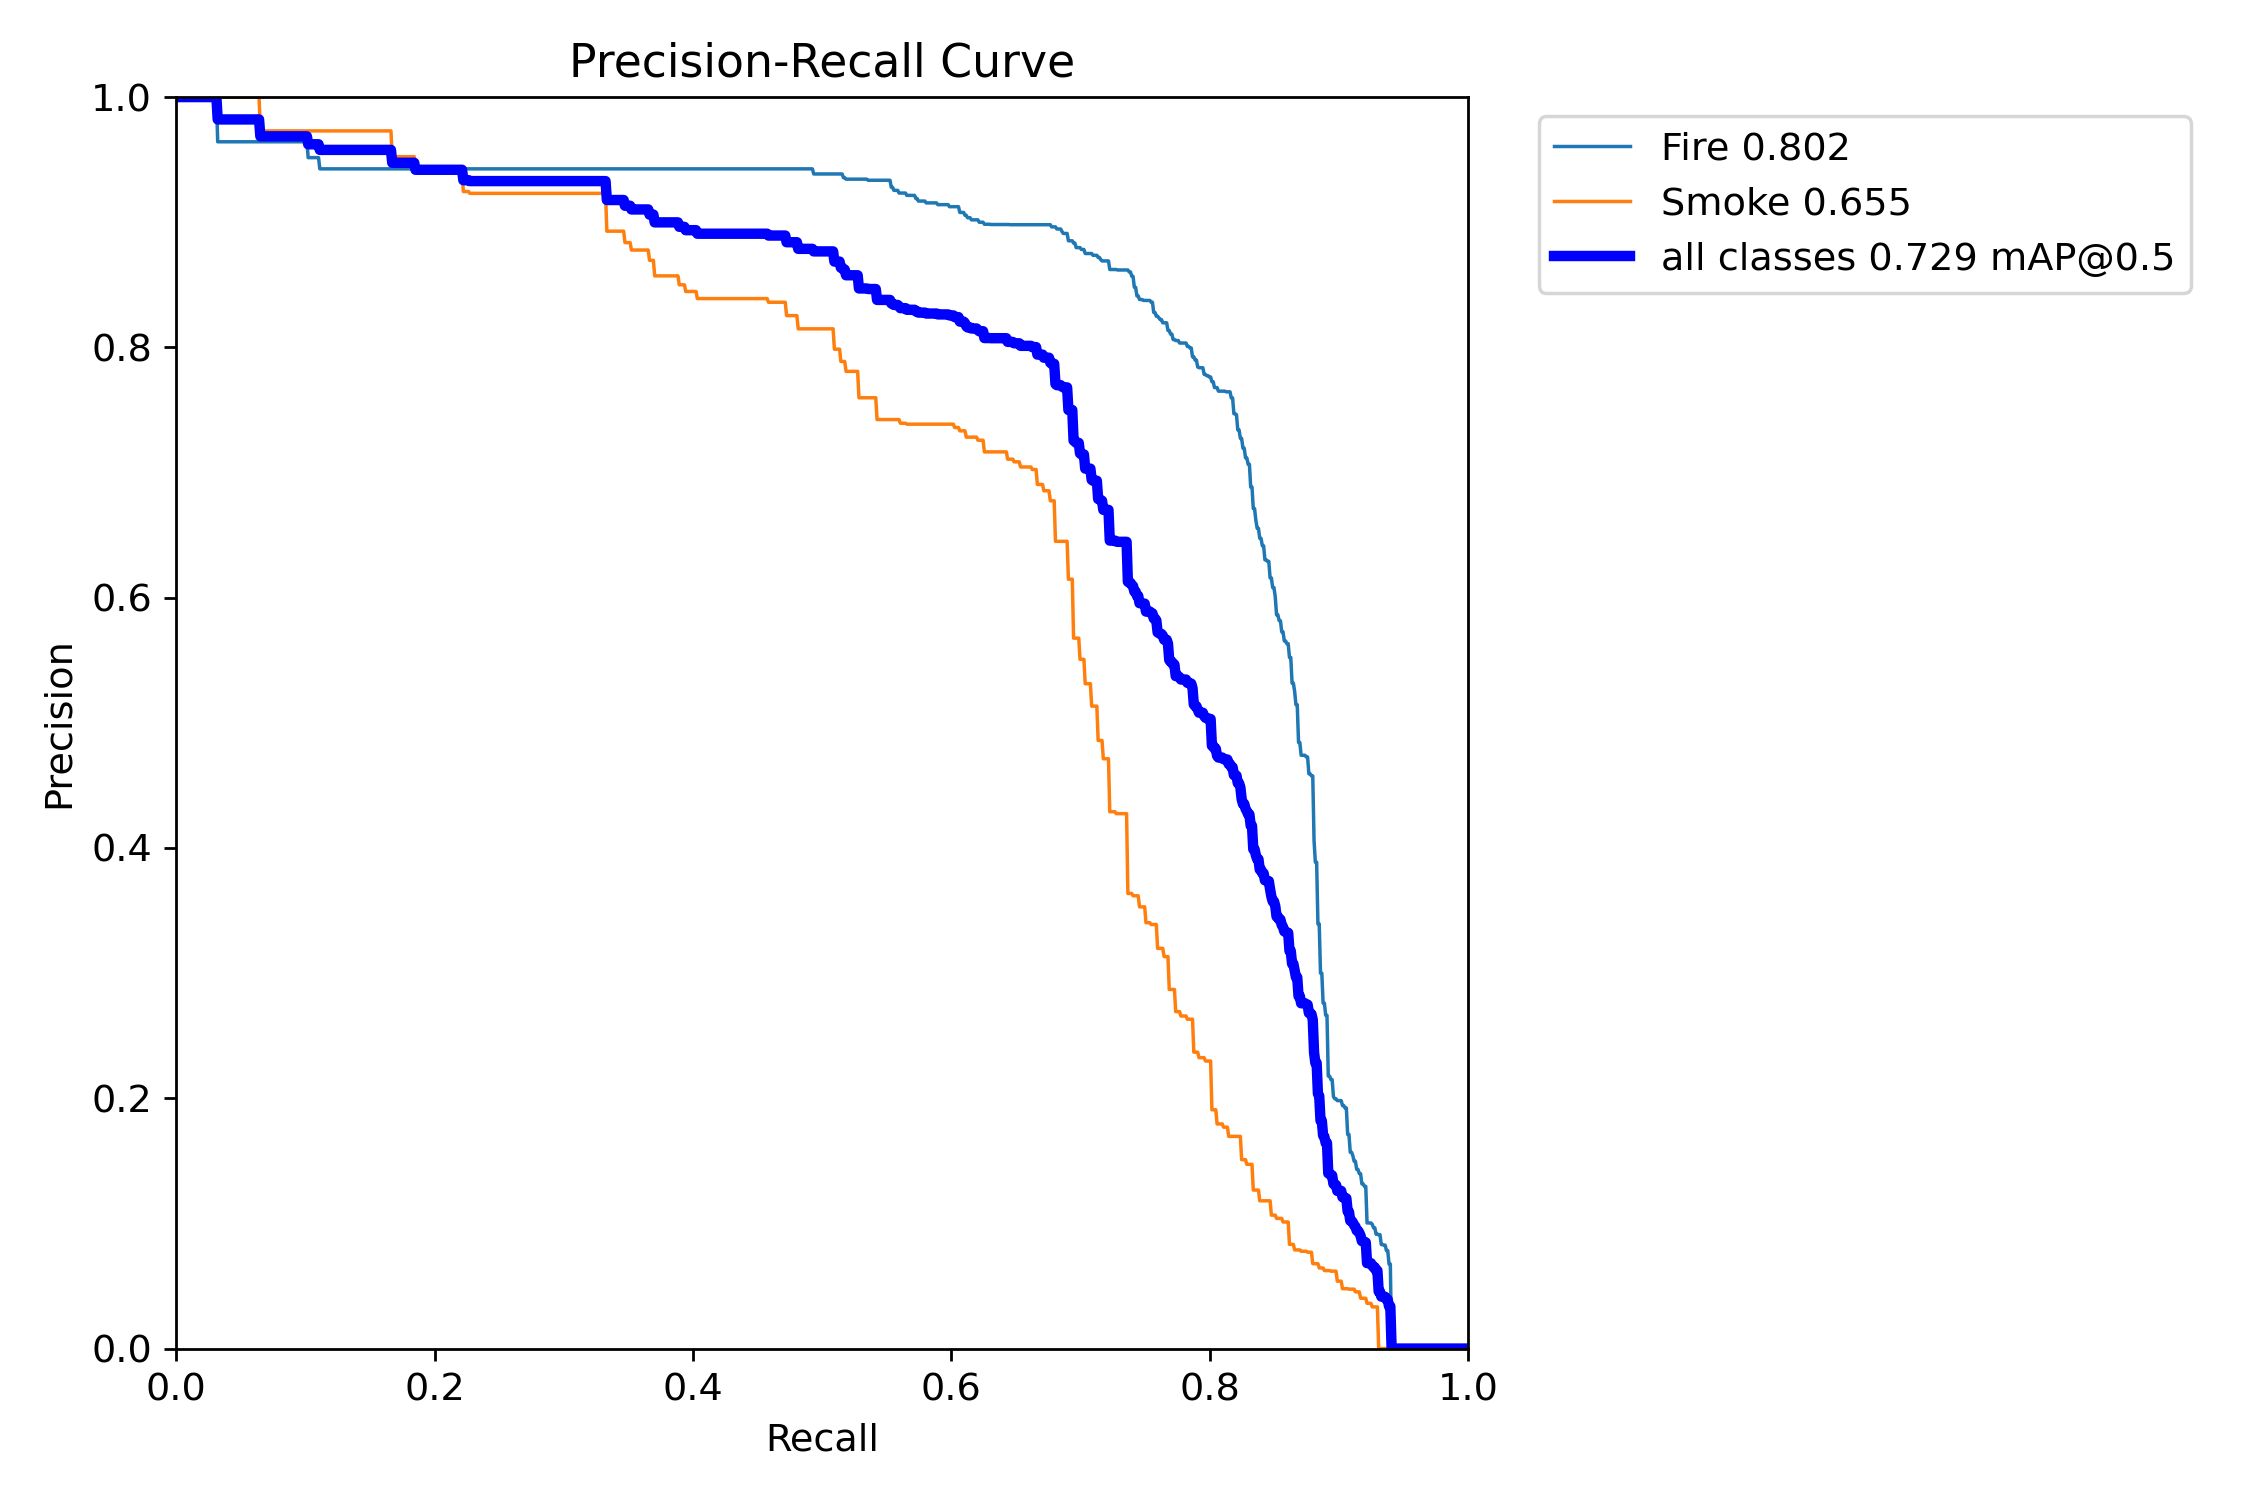

In [ ]:
from IPython.display import Image, display

display(Image(
    "/content/runs/detect/val-2/BoxP_curve.png",
    width=500
))

display(Image(
    "/content/runs/detect/val-2/BoxR_curve.png",
    width=500
))

display(Image(
    "/content/runs/detect/val-2/BoxF1_curve.png",
    width=500
))

display(Image(
    "/content/runs/detect/val-2/BoxPR_curve.png",
    width=500
))

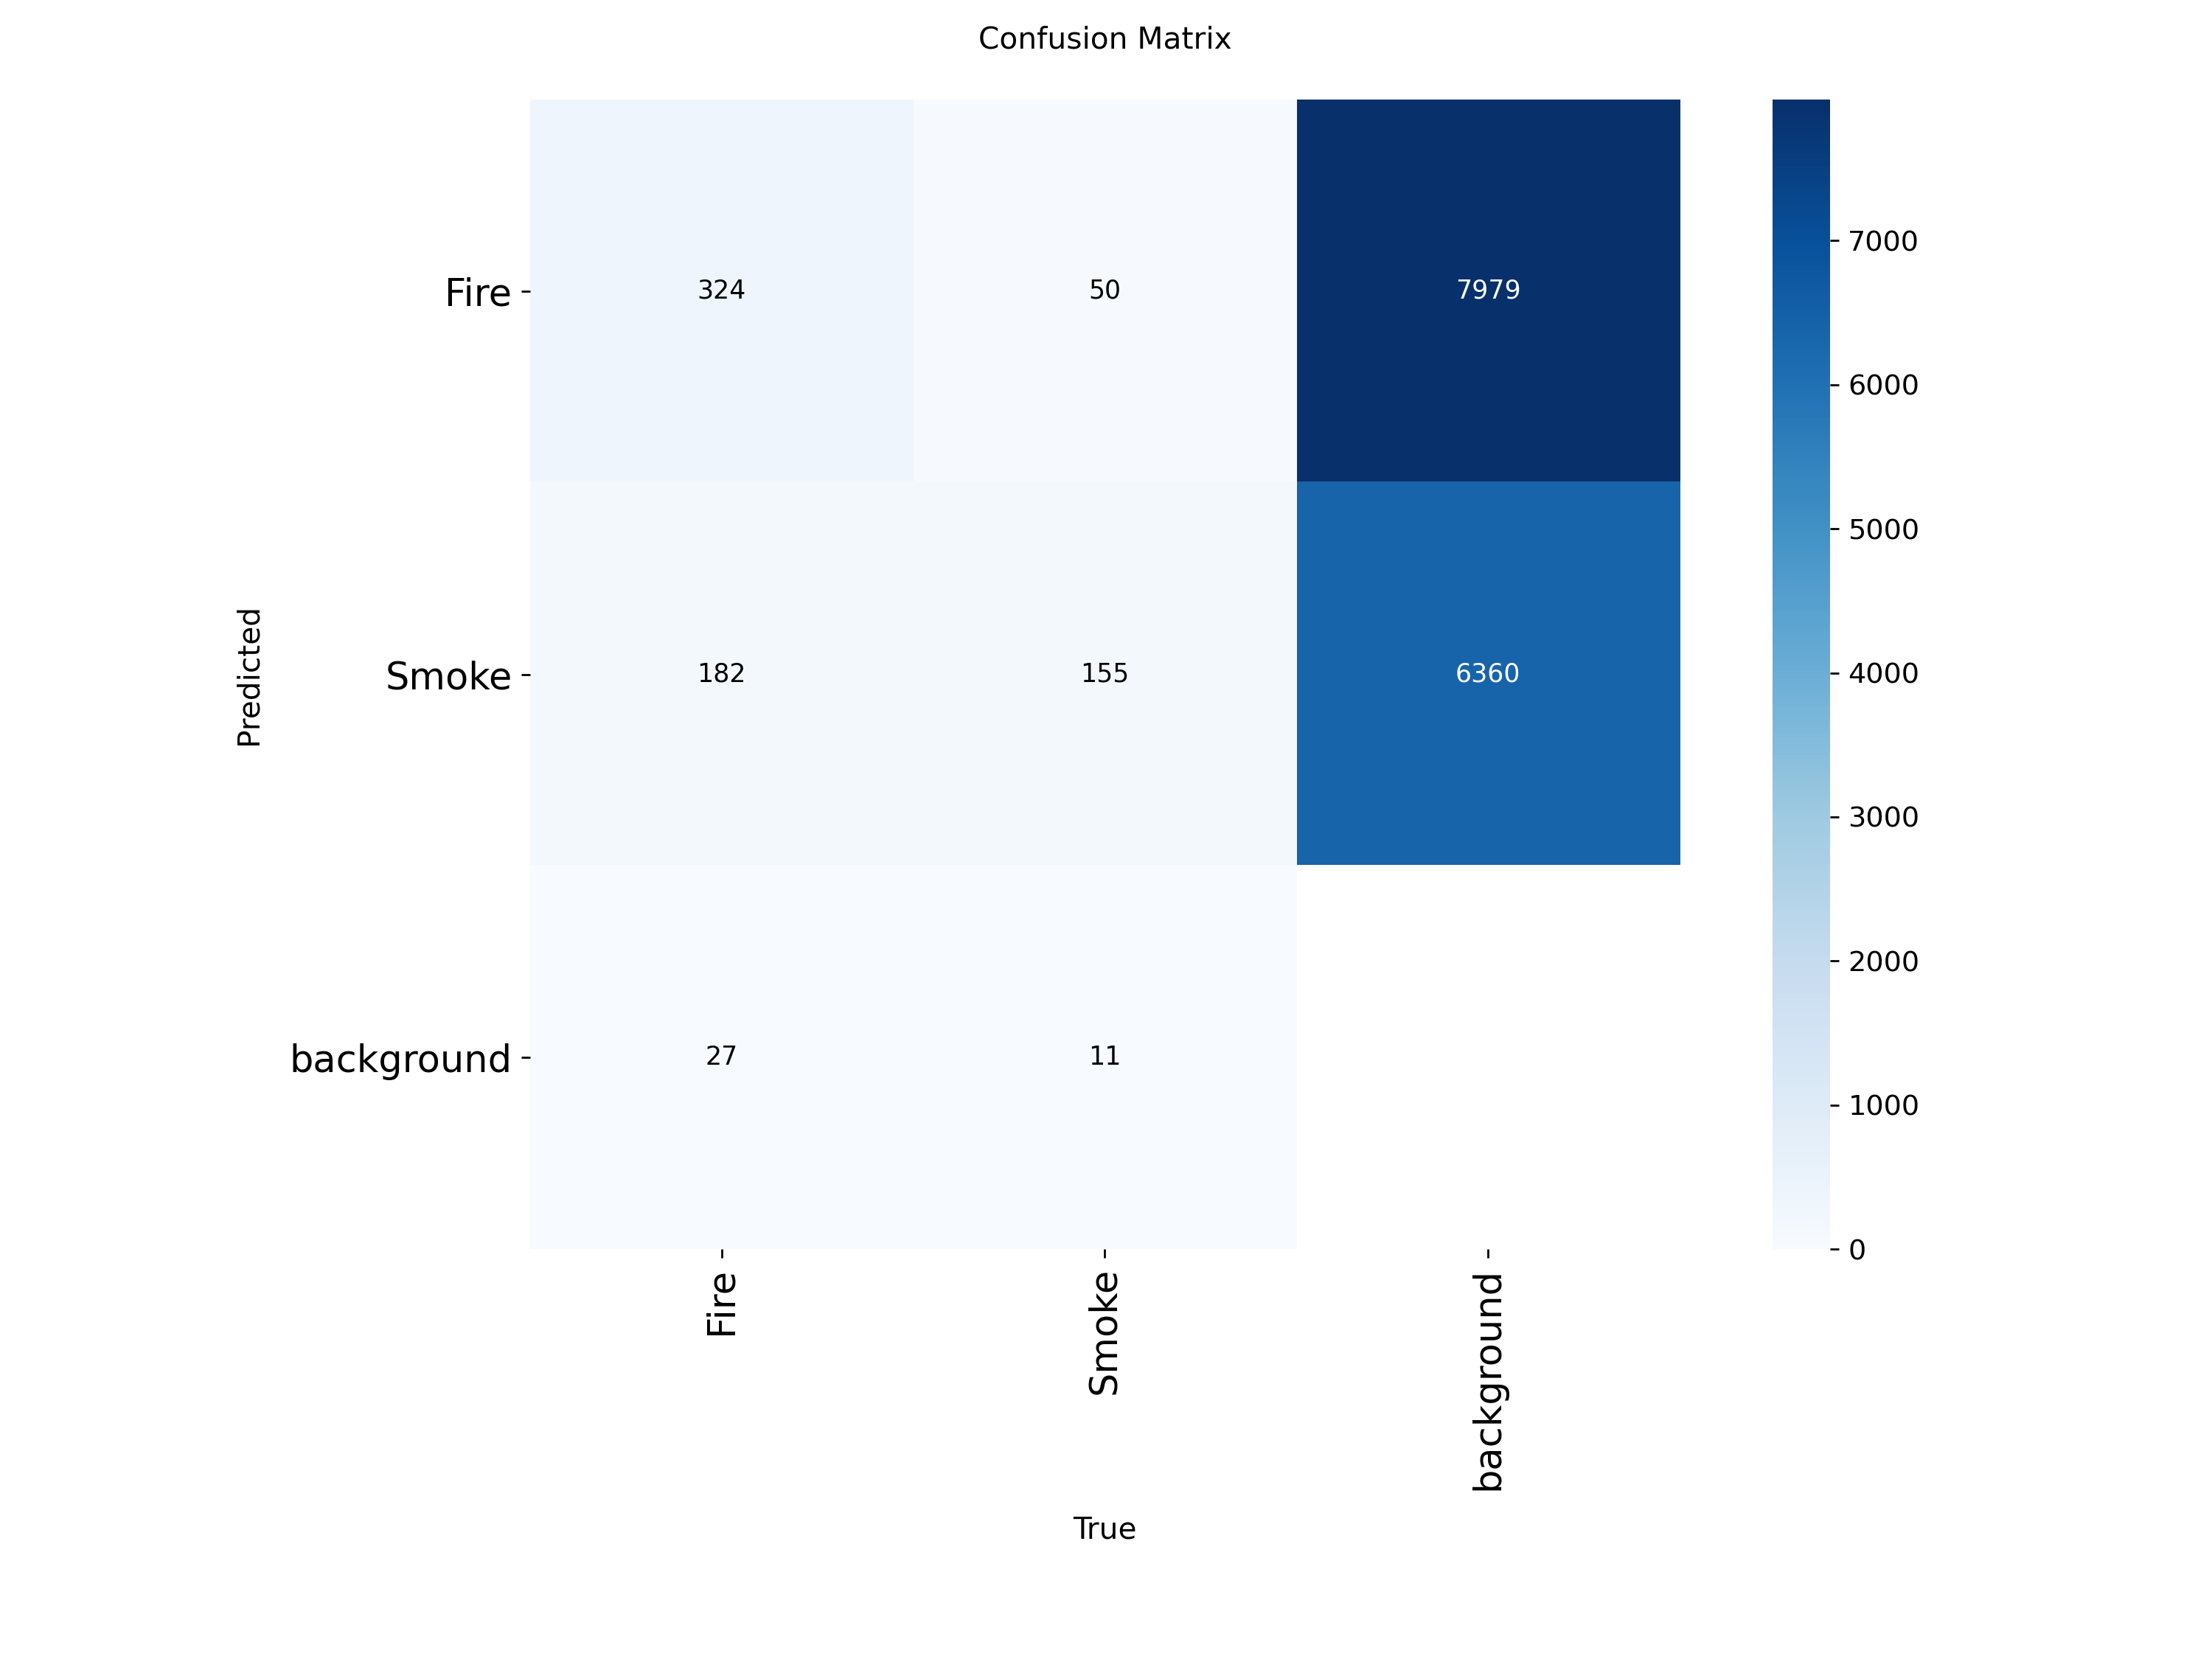

In [ ]:
from IPython.display import Image, display

display(Image(
    "/content/runs/detect/val-2/confusion_matrix.png",
    width=600
))

In [ ]:
print(metrics.confusion_matrix.matrix)

[[        324          50        7979]
 [        182         155        6360]
 [         27          11           0]]


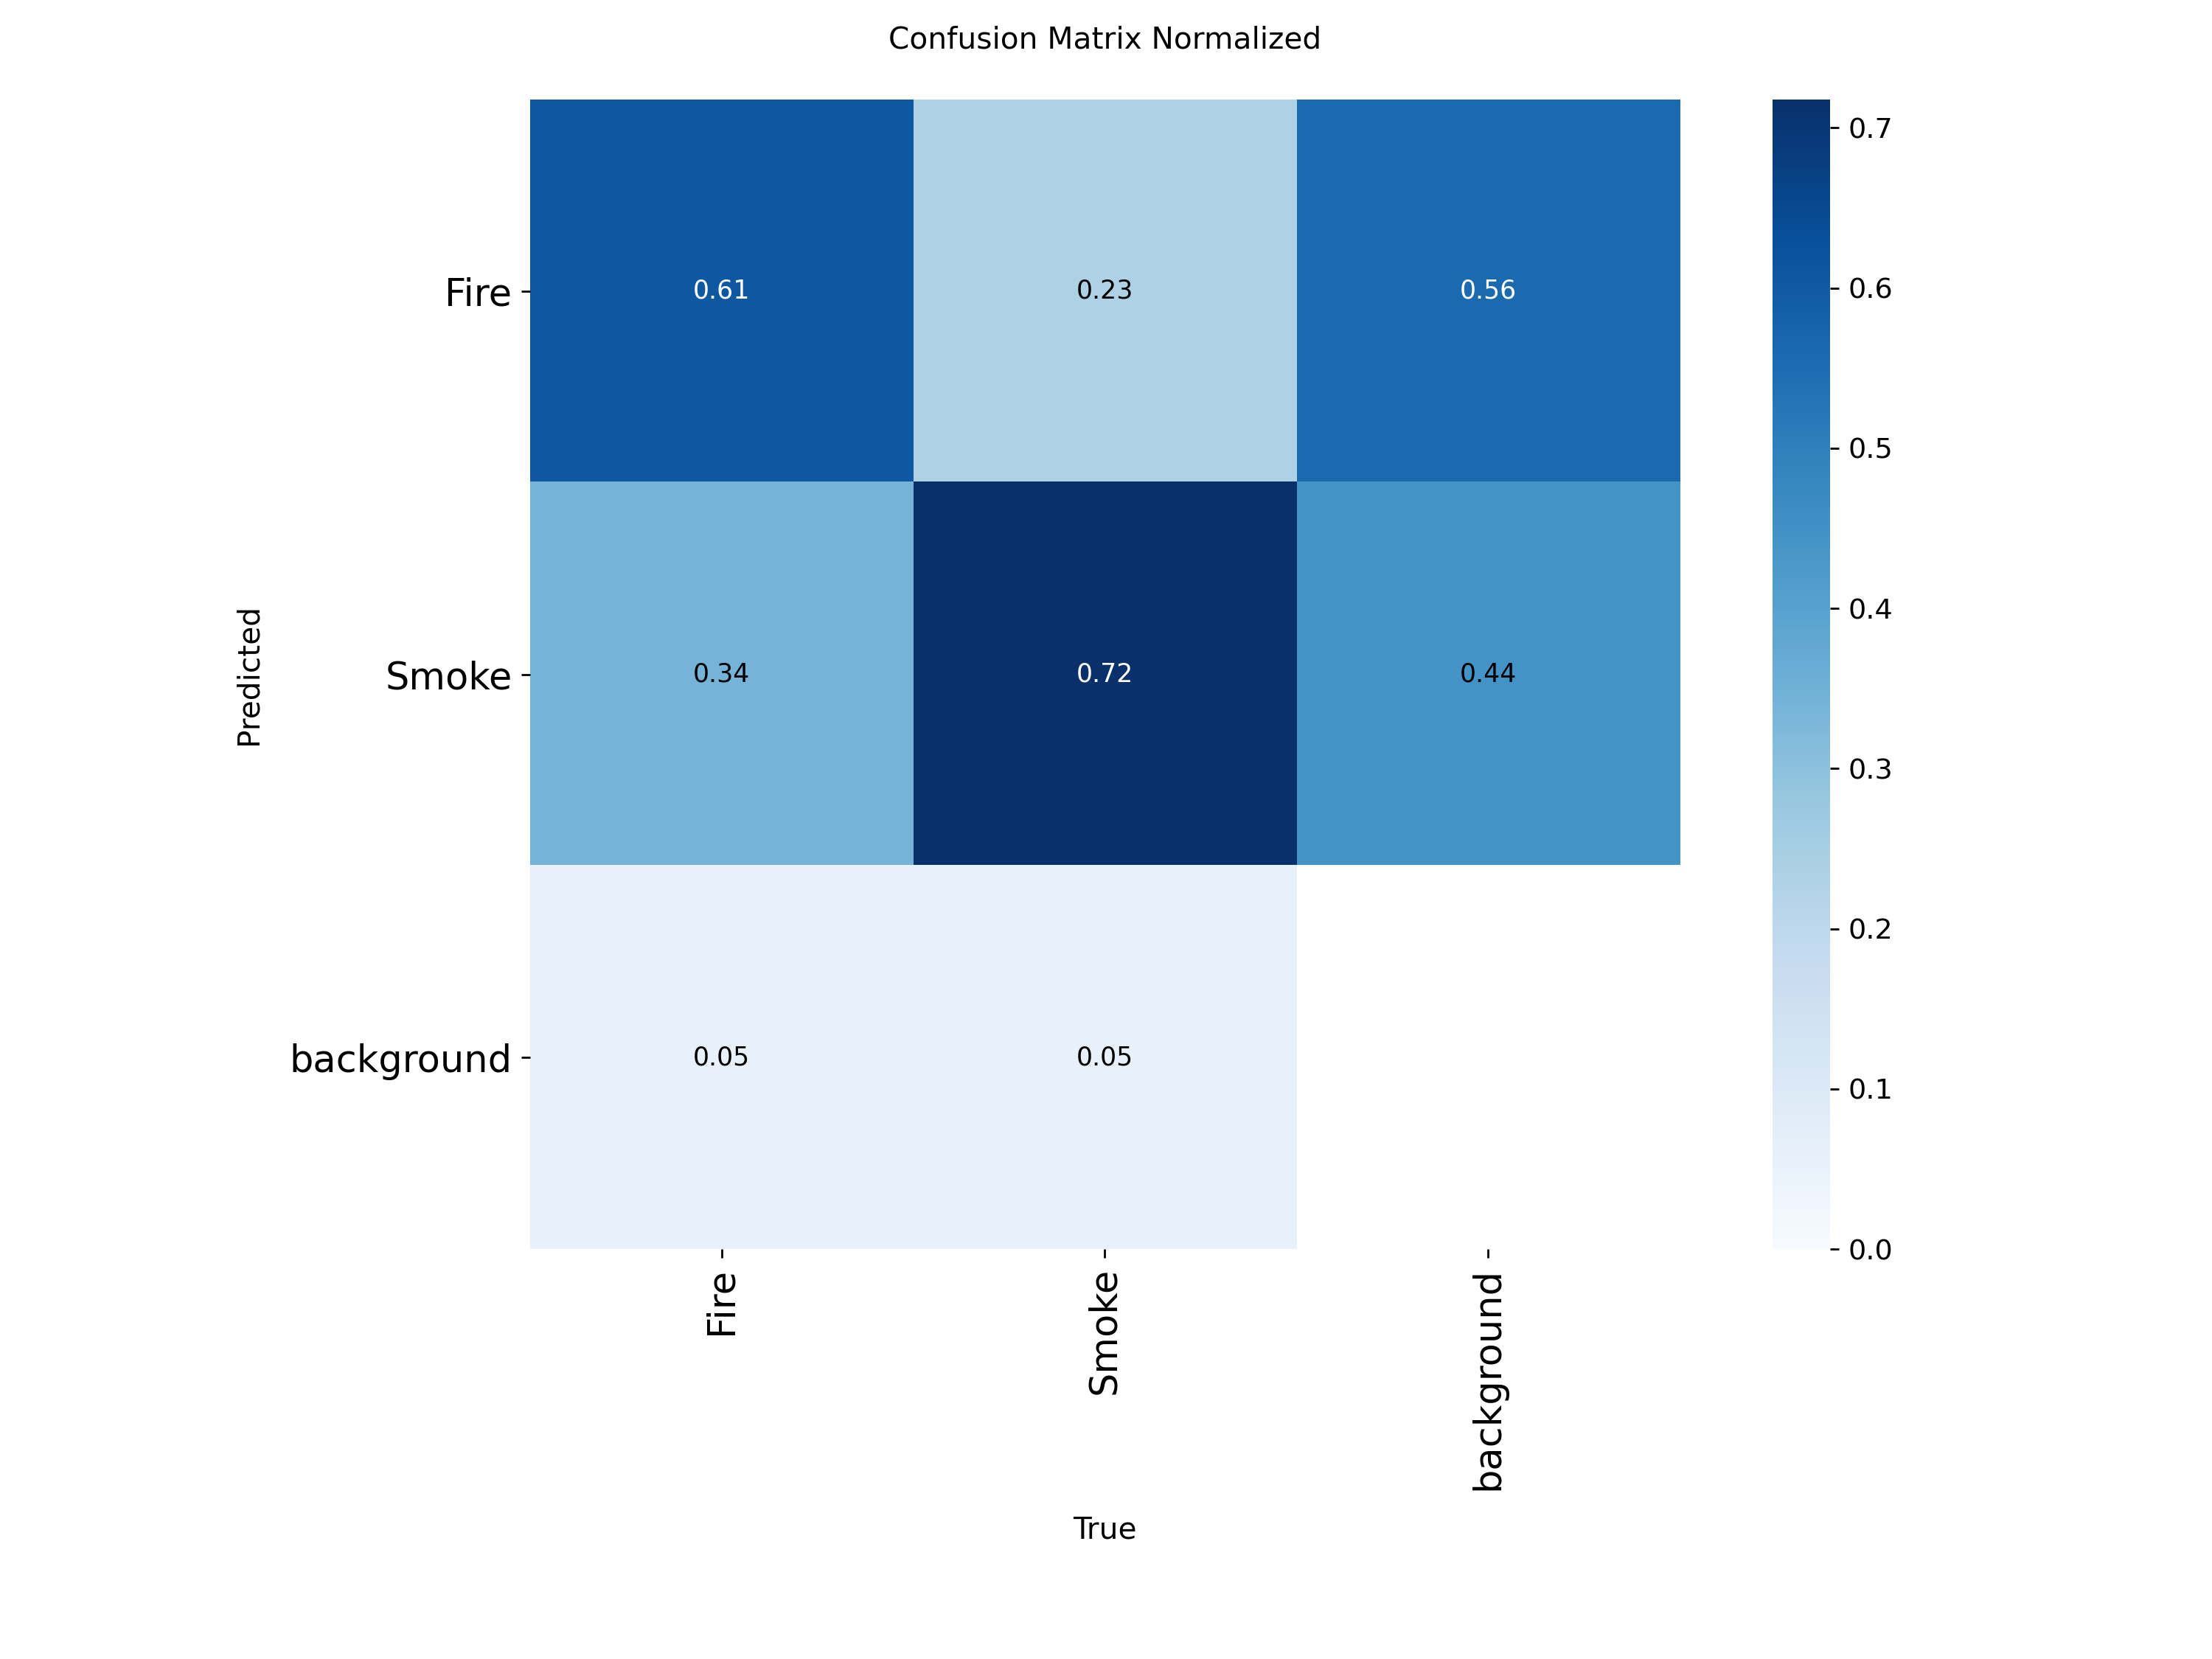

In [ ]:
from IPython.display import Image, display

display(Image(
    "/content/runs/detect/val-2/confusion_matrix_normalized.png",
    width=600
))

Evaluation Results
The model was evaluated on the test dataset containing 434 images and 749 instances. The model achieved a Precision of 74.59%, Recall of 72.04%, mAP@50 of 72.87%, and mAP@50-95 of 42.33%. The results indicate that the model performs better in detecting Fire than Smoke.